# Tune an IMSTE embedding on an MNIST-family dataset

Choose `MNIST`, `Fashion-MNIST`, or `Kuzushiji-MNIST` in the data cell below. The default search balances 5-fold k-NN accuracy (60%) and robust spatial coverage (40%). It fits each trial for the estimator's default 200 epochs.

Install the optional optimizer with `python -m pip install 'imste[tuning]'` if needed.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / 'notebooks' / 'src' / 'digits_sweep.py').is_file()
)
sys.path.insert(0, str(repo_root / 'notebooks' / 'src'))
sys.path.insert(0, str(repo_root))

from digits_sweep import (
    MNIST_FAMILY_DATASETS,
    load_mnist_per_class_data,
    load_mnist_family_data,
    make_live_tuning_display,
    plot_mnist_embedding,
)
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.visualization import render_datashader_embedding


## Choose and prepare the data

Choose one of `MNIST_FAMILY_DATASETS` below. Sampling is deterministic and balanced; the default is 2,000 images per class. The helper uses the project cache when available and downloads the selected dataset otherwise.

In [2]:
DATASET = 'Fashion-MNIST'  # Also: 'Fashion-MNIST' or 'Kuzushiji-MNIST'
SAMPLES_PER_CLASS = 200
RANDOM_STATE = 42

if DATASET not in MNIST_FAMILY_DATASETS:
    raise ValueError(f'DATASET must be one of {MNIST_FAMILY_DATASETS}.')

X, y, data_info = load_mnist_per_class_data(
    samples_per_class=SAMPLES_PER_CLASS,
    random_state=RANDOM_STATE,
    dataset_name=DATASET,
)
print(
    f"Loaded {len(X):,} images from {data_info['dataset']} ({SAMPLES_PER_CLASS} per class; {X.shape[1]} pixel features)."
)
display(data_info['class_counts'].to_frame())

Loaded 2,000 images from Fashion-MNIST (200 per class; 784 pixel features).


,images
0,200
1,200
2,200
3,200
4,200
5,200
6,200
7,200
8,200
9,200


## Set up the search

The `.tune()` defaults search `n_msts` (3–30), `learning_rate` (0.01–0.1), `negative_ratio` (1–10), `gravity_strength` (0.0–1.0), and `mean_shift_iterations` (0–5). They run 40 total trials, with 20 initial Latin hypercube samples, `k=5`, and coverage weight 0.4. `mapper` uses the estimator default of 200 epochs per fit.

In [3]:
mapper = IteratedMinimumSpanningTreeEmbedder(
    random_state=RANDOM_STATE,
    device='auto',
)

## Watch intermediate results

The table reports accuracy, spatial coverage, and the weighted objective after every trial. The plot updates when a trial improves the combined objective.

**Trial 40/40** — accuracy: 0.746; coverage: 0.303; objective: 0.569; best objective: 0.571

,accuracy,coverage,objective,best objective,n_msts,learning_rate,negative_ratio,gravity_strength,mean_shift_iterations
trial,,,,,,,,,
1,0.7005,0.078786,0.451814,0.451814,8,0.057692,2,0.601440,4
2,0.7275,0.086145,0.470958,0.470958,9,0.074113,7,0.426916,5
3,0.7180,0.125678,0.481071,0.481071,5,0.054781,9,0.105303,4
4,0.6795,0.159425,0.471470,0.481071,23,0.012894,5,0.397778,1
5,0.7125,0.048149,0.446760,0.481071,18,0.044585,3,0.687778,2
6,0.7095,0.077178,0.456571,0.481071,19,0.091084,5,0.499717,3
7,0.6970,0.120815,0.466526,0.481071,6,0.023630,6,0.519168,2
8,0.7295,0.191295,0.514218,0.514218,14,0.062891,8,0.324810,0
9,0.7040,0.028405,0.433762,0.514218,14,0.019763,4,0.956438,3


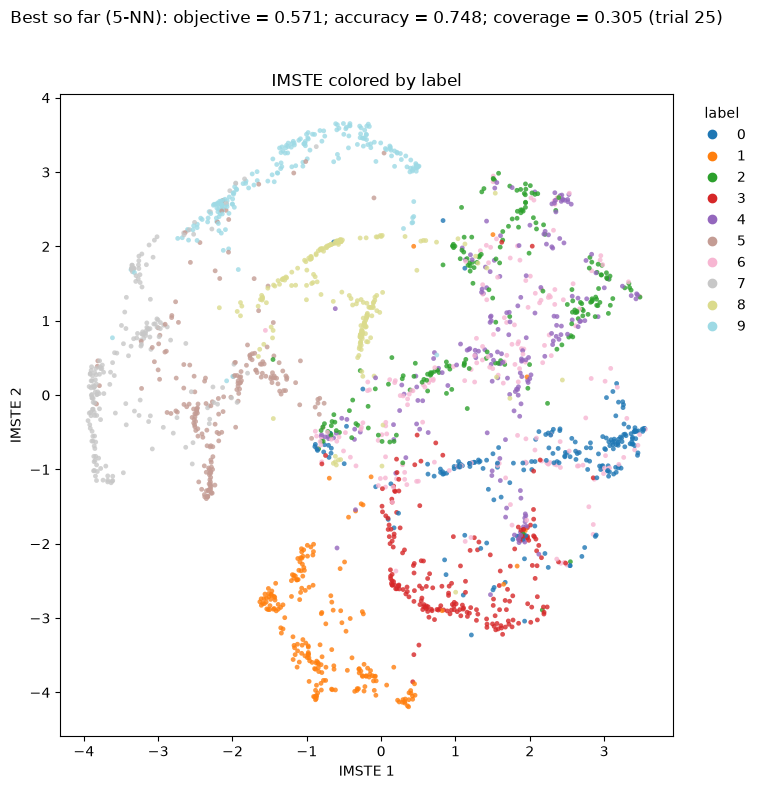

Search and final refit completed in 0.6 minutes


In [4]:
show_trial, trial_rows = make_live_tuning_display(
    y, figsize=(12, 8)
)

started = time.perf_counter()
search = mapper.tune(
    X, y,
    trial_callback=show_trial,
)
elapsed = time.perf_counter() - started
print(f'Search and final refit completed in {elapsed / 60:.1f} minutes')

## Best result

The estimator is refitted on all selected images using the configuration with the highest weighted objective. The returned result retains the separate accuracy, coverage, and combined scores.

Best 5-fold 5-NN accuracy: 0.748
Best spatial coverage: 0.305
Best combined objective: 0.571


,best value
n_msts,3.0
learning_rate,0.1
negative_ratio,10.0
gravity_strength,0.0
mean_shift_iterations,0.0


(<Figure size 1200x800 with 1 Axes>,
 array([[<Axes: title={'center': 'IMSTE colored by label'}, xlabel='IMSTE 1', ylabel='IMSTE 2'>]],
       dtype=object))

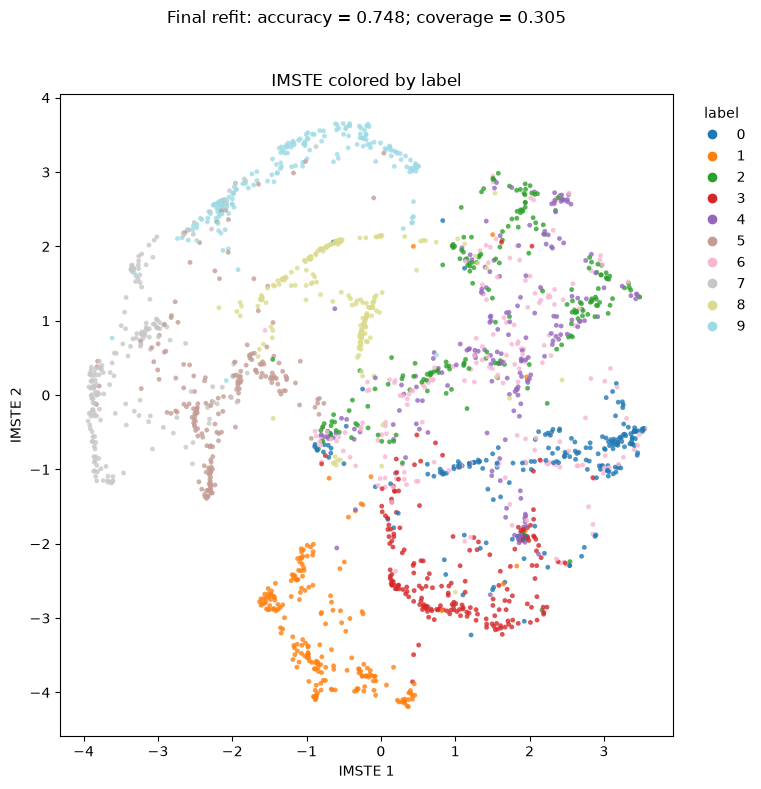

In [5]:
print(f"Best 5-fold {search.k}-NN accuracy: {search.best_accuracy:.3f}")
print(f"Best spatial coverage: {search.best_coverage:.3f}")
print(f"Best combined objective: {search.best_objective:.3f}")
display(pd.Series(search.best_params, name='best value').to_frame())
plot_mnist_embedding(
    mapper.embedding_, y,
    title=(
        f'Final refit: accuracy = {search.best_accuracy:.3f}; '
        f'coverage = {search.best_coverage:.3f}'
    ),
    figsize=(12, 8),
)

## Refit on the full dataset

After tuning on the selected balanced sample, load every row from the chosen dataset and fit the selected parameters again. The live search scores above are measured on the tuning sample; this final embedding uses the full dataset.

Refit on 70,000 Fashion-MNIST images in 0.1 minutes


,images
0,7000
1,7000
2,7000
3,7000
4,7000
5,7000
6,7000
7,7000
8,7000
9,7000


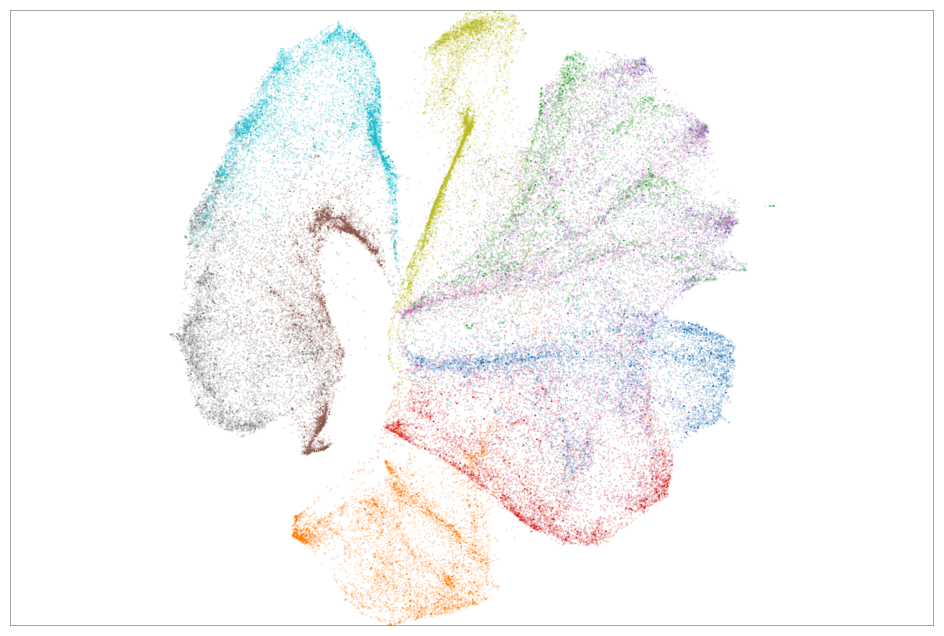

In [6]:
X_full, y_full, full_data_info = load_mnist_family_data(DATASET)
mapper.set_params(**search.best_params)

started = time.perf_counter()
mapper.fit(X_full)
elapsed = time.perf_counter() - started
print(
    f"Refit on {len(X_full):,} {full_data_info['dataset']} images "
    f"in {elapsed / 60:.1f} minutes"
)
display(full_data_info['class_counts'].to_frame())
s = 1.5
full_image = render_datashader_embedding(
    mapper.embedding_, y_full,
    width=int(1800*s), height=int(1200*s),
    preserve_aspect=True, min_alpha=60, spread_px=2,
)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(full_image.to_pil())
ax.set_axis_off()
display(fig)
plt.close(fig)